In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

In [11]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_normalizados.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, 'espectros_msc_signal.csv')

In [12]:
df = pd.read_csv(input_path)
data = df.values
data

array([[6.2146544e-05, 1.8202722e-01, 1.7842272e-01, ..., 1.7345099e-01,
        1.7668262e-01, 1.8401591e-01],
       [0.0000000e+00, 1.6711205e-01, 1.6997080e-01, ..., 1.6164315e-01,
        1.6412902e-01, 1.6294824e-01],
       [1.8059786e-01, 1.8345658e-01, 1.8084644e-01, ..., 1.8643962e-01,
        1.7326456e-01, 1.8028712e-01],
       ...,
       [1.7469393e-01, 1.7780125e-01, 1.7786340e-01, ..., 1.7581257e-01,
        1.7258094e-01, 1.7195947e-01],
       [1.9545087e-01, 1.8842831e-01, 1.8867690e-01, ..., 1.8370518e-01,
        1.8793114e-01, 2.0054689e-01],
       [1.6400473e-01, 1.5984091e-01, 1.6139457e-01, ..., 1.5480703e-01,
        1.4828165e-01, 1.4685228e-01]], shape=(92480, 256))

In [13]:
ref = np.mean(data, axis=0)

# Lista para espectros corrigidos
msc_corrected = []

In [14]:
for spectrum in data:
    # Regressão linear simples: spectrum = a*ref + b
    a, b = np.polyfit(ref, spectrum, 1)
    corrected = (spectrum - b) / a
    msc_corrected.append(corrected)

msc_corrected = np.array(msc_corrected)

In [15]:
print(f"Forma dos dados: {data.shape}")
print(f"Faixa de valores: [{data.min():.6f}, {data.max():.6f}]")
print(f"Faixa de valores: [{msc_corrected.min():.6f}, {msc_corrected.max():.6f}]")

Forma dos dados: (92480, 256)
Faixa de valores: [0.000000, 1.000000]
Faixa de valores: [-45003.615557, 23823.620426]


In [16]:
df_espectros = pd.DataFrame(msc_corrected, columns=df.columns)
bandas_numeros = np.arange(len(df.columns))


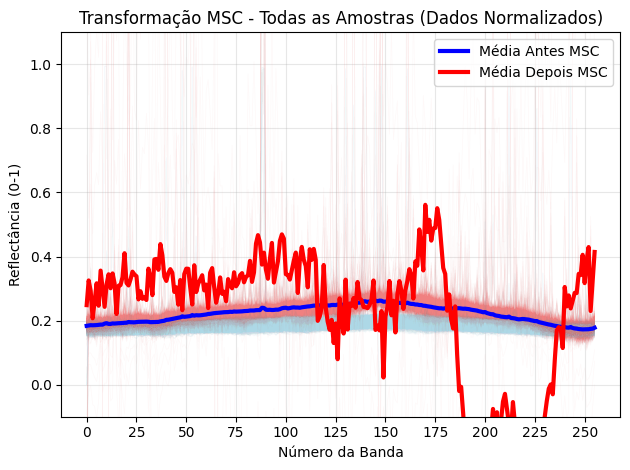

In [8]:
# Plotar todas as amostras (transparentes)
for i in range(min(1000, df.shape[0])):  # Limitar para não sobrecarregar
    plt.plot(bandas_numeros, df.iloc[i, :], color='lightblue', alpha=0.05, linewidth=0.5)
    plt.plot(bandas_numeros, df_espectros.iloc[i, :], color='lightcoral', alpha=0.05, linewidth=0.5)

# Plotar médias
media_antes = df.mean(axis=0)
media_depois = df_espectros.mean(axis=0)

plt.plot(bandas_numeros, media_antes, color='blue', linewidth=3, label='Média Antes MSC')
plt.plot(bandas_numeros, media_depois, color='red', linewidth=3, label='Média Depois MSC')

plt.xlabel('Número da Banda')
plt.ylabel('Reflectância (0-1)')
plt.title('Transformação MSC - Todas as Amostras (Dados Normalizados)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.ylim(-0.1, 1.1)  # Forçar escala 0-1

# Melhorar eixo X
plt.xticks(bandas_numeros[::len(bandas_numeros)//10])

plt.tight_layout()
plt.show()